![Router](./Router.png)

### Router

<h6>
Graph uses <b>messages</b> as state and chat model with bound tools.<br>
The Chat model routes between a direct response or a tool call based upon the user input.
</h6>

In [18]:
import os


def load_env():
    """Load environment variables from the local .env file."""
    env_path = "C:\\Users\\felip\\Documents\\introduction_langgraph\\.env"

    with open(env_path, "r") as file:
        for line in file:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            key, value = line.split("=", 1)
            os.environ[key.strip()] = value.strip().strip('"').strip("'")

load_env()

### Tools

<h6>
Tools are needed whenever you want a model to control parts of your code or call out to external API.<br>
Pass any Python function into <b>ChatModel.bind_tools()</b>
</h6>

In [19]:
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b

### Chat Models
<h6>
Chat models can use a sequence of message as input and support message roles, as discussed above.<br>
</h6>

In [20]:
from langchain_core.messages import AIMessage, HumanMessage


messages = [AIMessage(content=f"So you said you were researching ocean mammals?", name="Model")]
messages.extend([HumanMessage(content=f"Yes, that's right.", name="Lance")])
messages.extend([AIMessage(content=f"Great, what would you like to learn about.", name="Model")])
messages.extend([HumanMessage(content=f"I want to learn about the best place to see Orcas in the US.", name="Lance")])

for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Model

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, that's right.
================================== Ai Message ==================================
Name: Model

Great, what would you like to learn about.
================================ Human Message =================================
Name: Lance

I want to learn about the best place to see Orcas in the US.


In [21]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage

llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash", google_api_key=os.getenv("GOOGLE_API_KEY")) # gemini-2.5-flash
llm_tools = llm.bind_tools([multiply])
response = llm.invoke(messages)
type(response)

tool_call = llm_tools.invoke([HumanMessage(content="What is 2 multiplied by 10?", name="Lance")])

### ToolNode
<h6>
The built-in <b>tools_condition</b> is used as a conditional edge.<br>
</h6>

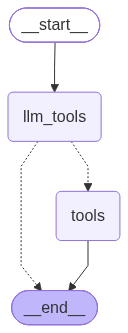

In [22]:
from IPython.display import Image, display
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import MessagesState, StateGraph, START, END

# State
class GraphState(MessagesState):
    pass

# Node
def tool_calling_llm(state: GraphState):
    """Invoke the model with the current message state and return the response."""
    result = llm_tools.invoke(state["messages"])
    return {"messages": [result]}

# Graph
builder = StateGraph(GraphState)
builder.add_node("llm_tools", tool_calling_llm)
builder.add_node("tools", ToolNode([multiply]))
builder.add_edge(START, "llm_tools")
builder.add_conditional_edges("llm_tools", tools_condition)
builder.add_edge("tools", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))